# Earth Detectives · Caderno de inspeção
## O que temos em mãos?
**Inventário, cobertura, integridade e visualização dos dados originais.**

Este caderno inicia a inspeção conjunta solicitada, sem aplicar limpeza, preenchimento, interpolação, agregação, climatologia ou classificação ENSO própria. As figuras são descritivas. Nenhum arquivo em `data/raw` é escrito.

**Escopo:** RONI histórico + pequenas amostras NASA de dezembro/2015. A região terrestre `brasilia_smoke` é uma caixa de teste, não uma bacia escolhida para estudo.

Execute todas as células com o kernel Python da `.venv`. Instalação reproduzível: `uv pip install --python .venv/bin/python -r requirements-notebook-lock.txt`. Não é necessário token ou acesso à rede para este caderno; os arquivos brutos precisam existir localmente.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import netCDF4
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'config/datasets.yaml').is_file()), None)
assert ROOT is not None, 'Abra este notebook dentro do repositório.'
DATA = ROOT / 'data'
manifest = json.loads((DATA / 'metadata/manifest.json').read_text())
files = manifest['files']
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_rows', 60)
plt.rcParams.update({'figure.facecolor': '#f5f7fb', 'axes.facecolor': '#ffffff',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'font.size': 10,
                     'figure.dpi': 110, 'axes.grid': False})
print(f'{len(files)} arquivos locais · {sum(f["size_bytes"] for f in files):,} bytes')

9 arquivos locais · 10,846,669 bytes


## 1 · Cobertura temporal: disponível ≠ baixado
Um produto mensal pode ter apenas um timestamp representativo, embora sua cobertura seja o mês inteiro. O RONI usa trimestres sobrepostos, não observações mensais independentes. O MUR inclui 02/12 porque seu grânulo intersecta o pedido de 01/12; os registros nativos foram preservados.

In [2]:
coverage = []
for f in files:
    a = f['audit']
    coverage.append({'dataset': f['dataset'], 'arquivo': Path(f['path']).name,
                     'cobertura_grânulo': f.get('granule_observation_period'),
                     'tempos_no_arquivo': a.get('observation_period'),
                     'registros_temporais': a.get('temporal_records'),
                     'região': f['region']['id'], 'bytes': f['size_bytes']})
coverage = pd.DataFrame(coverage)
display(coverage)
collections = []
for path in sorted((DATA / 'metadata').glob('*_discovery.json')):
    meta = json.loads(path.read_text())
    collections.append({'dataset': path.name.replace('_discovery.json', ''),
                        'coleção': meta['collection_id'], **meta['available_period']})
display(Markdown('**Cobertura anunciada no catálogo (não significa que todo esse período foi baixado):**'))
display(pd.DataFrame(collections))

,dataset,arquivo,cobertura_grânulo,tempos_no_arquivo,registros_temporais,região,bytes
0,noaa_roni,series-1297887f581b6190.txt,None,"{'start': '1950-01', 'end': '2026-09'}",921.0,global_index,14752
1,noaa_roni,classification-45a29af6d57b0a23.html,None,None,NaN,global_index,98060
2,gpm_monthly,G2819757905-GES_DISC-0-8f2007f800b66fcd.nc4,"{'start': '2015-12-01T00:00:00.000Z', 'end': '2015-12-31T23:59:59.999Z'}","{'start': '2015-12-01 00:00:00', 'end': '2015-12-01 00:00:00'}",1.0,brasilia_smoke,44180
3,gldas,G1413724045-GES_DISC-0-30c622fdeaf2f759.nc4,"{'start': '2015-12-01T00:00:00.000Z', 'end': '2015-12-31T23:59:59.000Z'}","{'start': '2015-12-01 00:00:00', 'end': '2015-12-01 00:00:00'}",1.0,brasilia_smoke,83186
4,merra2,G1278026042-GES_DISC-0-8c42502466a03f93.nc4,"{'start': '2015-12-01T00:00:00.000Z', 'end': '2015-12-31T23:59:59.000Z'}","{'start': '2015-12-01 00:30:00', 'end': '2015-12-01 00:30:00'}",1.0,nino34,86639
5,gpm_daily,G2819929145-GES_DISC-0-ae19577ed64e4621.nc4,"{'start': '2015-12-01T00:00:00.000Z', 'end': '2015-12-01T23:59:59.999Z'}","{'start': '2015-12-01 00:00:00', 'end': '2015-12-01 00:00:00'}",1.0,brasilia_smoke,35863
6,gpm_daily,G2819921532-GES_DISC-0-49f3c33055e06667.nc4,"{'start': '2015-12-02T00:00:00.000Z', 'end': '2015-12-02T23:59:59.999Z'}","{'start': '2015-12-02 00:00:00', 'end': '2015-12-02 00:00:00'}",1.0,brasilia_smoke,35512
7,mur_sst,G2028180986-POCLOUD-0-44d51052179c5877.nc4,"{'start': '2015-11-30T21:00:00.000Z', 'end': '2015-12-01T21:00:00.000Z'}","{'start': '2015-12-01 09:00:00', 'end': '2015-12-01 09:00:00'}",1.0,nino34,5234208
8,mur_sst,G2028182364-POCLOUD-0-bd41c2b3be9cad25.nc4,"{'start': '2015-12-01T21:00:00.000Z', 'end': '2015-12-02T21:00:00.000Z'}","{'start': '2015-12-02 09:00:00', 'end': '2015-12-02 09:00:00'}",1.0,nino34,5214269


**Cobertura anunciada no catálogo (não significa que todo esse período foi baixado):**

,dataset,coleção,start,end
0,gldas,C1342986036-GES_DISC,2000-01-01T00:00:00.000Z,2026-07-31T23:59:59.000Z
1,gpm_daily,C2723754864-GES_DISC,1998-01-01T00:00:00.000Z,2025-09-30T23:59:59.999Z
2,gpm_monthly,C2723754851-GES_DISC,1998-01-01T00:00:00.000Z,2025-09-30T23:59:59.999Z
3,merra2,C1276812859-GES_DISC,1980-01-01T00:00:00.000Z,2026-09-30T23:59:59.000Z
4,mur_sst,C1996881146-POCLOUD,2002-05-31T21:00:00.000Z,2026-11-13T21:00:00.000Z


### O que ficou de fora
- Histórico NASA completo: somente as amostras acima foram transferidas. Elas não permitem avaliar tendências, sazonalidade, lacunas históricas ou comparar episódios ENSO.
- Região científica brasileira definitiva e auditoria de estações ANA/INMET.
- ANA, INMET, SMAP, MODIS/vegetação, NASA-SSH e outras camadas complementares.
- Máscara exata de polígonos: a automação usa o envelope da geometria; as amostras terrestres usam uma caixa provisória.
- Campos não solicitados: o subset NASA contém as variáveis prioritárias e coordenadas/auxiliares retornadas pelo provedor; não é uma cópia integral de todas as variáveis do produto global.
- Limpeza e padronização: nenhuma unidade foi convertida nos arquivos. IMERG mensal permanece em **mm/hr**, diário em **mm/day**, e MUR em **kelvin**.

## 2 · Integridade dos arquivos
O hash confirma que estamos olhando o mesmo conteúdo registrado na coleta. Não é um teste de qualidade climática.

In [3]:
def digest(path):
    h = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

integrity = pd.DataFrame([
    {'dataset': f['dataset'], 'arquivo': Path(f['path']).name,
     'existe': (DATA / f['path']).is_file(),
     'SHA256_confere': digest(DATA / f['path']) == f['sha256']}
    for f in files
])
display(integrity)
assert integrity['SHA256_confere'].all(), 'Há arquivo diferente do manifesto; investigue antes de analisar.'
original_hashes = {f['path']: f['sha256'] for f in files}

,dataset,arquivo,existe,SHA256_confere
0,noaa_roni,series-1297887f581b6190.txt,True,True
1,noaa_roni,classification-45a29af6d57b0a23.html,True,True
2,gpm_monthly,G2819757905-GES_DISC-0-8f2007f800b66fcd.nc4,True,True
3,gldas,G1413724045-GES_DISC-0-30c622fdeaf2f759.nc4,True,True
4,merra2,G1278026042-GES_DISC-0-8c42502466a03f93.nc4,True,True
5,gpm_daily,G2819929145-GES_DISC-0-ae19577ed64e4621.nc4,True,True
6,gpm_daily,G2819921532-GES_DISC-0-49f3c33055e06667.nc4,True,True
7,mur_sst,G2028180986-POCLOUD-0-44d51052179c5877.nc4,True,True
8,mur_sst,G2028182364-POCLOUD-0-bd41c2b3be9cad25.nc4,True,True


## 3 · RONI histórico original
A linha abaixo mostra apenas a série oficial. Não atribuímos fases por limiares nem tratamos trimestres sobrepostos como observações independentes. A classificação oficial permanece no HTML complementar.

,SEAS,YR,ANOM,mês_central,data_central
0,DJF,1950,-1.19,1,1950-01-01
1,JFM,1950,-1.08,2,1950-02-01
2,FMA,1950,-0.96,3,1950-03-01
3,MAM,1950,-1.00,4,1950-04-01
4,AMJ,1950,-0.99,5,1950-05-01
5,MJJ,1950,-0.75,6,1950-06-01
6,JJA,1950,-0.38,7,1950-07-01
7,JAS,1950,-0.32,8,1950-08-01


,registros,duplicatas_ano_trimestre,ANOM_nulo,sentinelas_conhecidas,início,fim
0,921,0,0,0,1950-01-01,2026-09-01


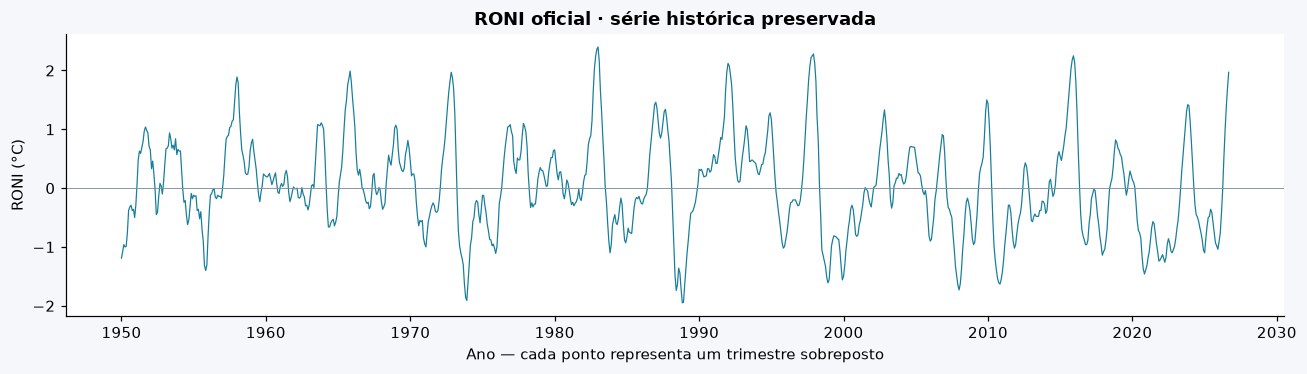

In [4]:
roni_file = next(f for f in files if f['dataset'] == 'noaa_roni' and f['path'].endswith('.txt'))
roni = pd.read_csv(DATA / roni_file['path'], sep=r'\s+')
seasons = 'DJF JFM FMA MAM AMJ MJJ JJA JAS ASO SON OND NDJ'.split()
roni['mês_central'] = roni['SEAS'].map({s: i + 1 for i, s in enumerate(seasons)})
roni['data_central'] = pd.to_datetime(dict(year=roni['YR'], month=roni['mês_central'], day=1))
display(roni.head(8))
display(pd.DataFrame([{'registros': len(roni),
    'duplicatas_ano_trimestre': int(roni.duplicated(['YR', 'SEAS']).sum()),
    'ANOM_nulo': int(roni['ANOM'].isna().sum()),
    'sentinelas_conhecidas': int(roni['ANOM'].isin([-99.9, -999.0]).sum()),
    'início': roni['data_central'].min(), 'fim': roni['data_central'].max()}]))
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(roni['data_central'], roni['ANOM'], color='#167d9a', linewidth=.8)
ax.axhline(0, color='#8190a2', linewidth=.6)
ax.set(title='RONI oficial · série histórica preservada', ylabel='RONI (°C)',
       xlabel='Ano — cada ponto representa um trimestre sobreposto')
fig.tight_layout()
plt.show()

## 4 · Variáveis, valores ausentes e faixas declaradas
Lemos os valores **empacotados originais**, com escala automática desligada. Contamos NaN/infinito, `_FillValue` e `missing_value` sem substituí-los. Violações de `valid_min`, `valid_max` ou `valid_range`, quando presentes, são mostradas separadamente; não são apagadas.

Mínimo/máximo físicos abaixo usam apenas a decodificação declarada `packed × scale_factor + add_offset` em memória. Isso não é limpeza nem conversão de unidade. A unidade original permanece igual.

In [5]:
def field(root, requested):
    parts = requested.split('/')
    group = root
    for part in parts[:-1]:
        group = group.groups[part]
    return group.variables[parts[-1]]

def read_field(entry, name):
    with netCDF4.Dataset(DATA / entry['path']) as root:
        var = field(root, name)
        var.set_auto_maskandscale(False)
        raw = np.asarray(var[:])
        attrs = {key: var.getncattr(key) for key in var.ncattrs()}
        dims = tuple(var.dimensions)
    missing = ~np.isfinite(raw) if np.issubdtype(raw.dtype, np.floating) else np.zeros(raw.shape, bool)
    for key in ('_FillValue', 'missing_value'):
        for value in np.asarray(attrs.get(key, [])).reshape(-1):
            missing |= raw == value
    return raw, missing, attrs, dims

rows = []
for entry in files:
    if entry['dataset'] == 'noaa_roni':
        continue
    for name in entry['audit']['variables']:
        raw, missing, attrs, dims = read_field(entry, name)
        valid = raw[~missing]
        low = attrs.get('valid_min')
        high = attrs.get('valid_max')
        if 'valid_range' in attrs:
            low, high = np.asarray(attrs['valid_range']).reshape(-1)[:2]
        violations = np.zeros(valid.shape, bool)
        if low is not None:
            violations |= valid < low
        if high is not None:
            violations |= valid > high
        scale, offset = attrs.get('scale_factor', 1), attrs.get('add_offset', 0)
        extrema = np.array([valid.min(), valid.max()], dtype=float) * scale + offset if valid.size else np.array([np.nan, np.nan])
        rows.append({'dataset': entry['dataset'], 'arquivo': Path(entry['path']).name,
                     'variável': name, 'unidade': attrs.get('units'), 'dimensões': str(dims),
                     'shape': str(raw.shape), 'dtype_original': str(raw.dtype),
                     'células': raw.size, 'ausentes': int(missing.sum()),
                     'ausentes_%': round(100 * missing.sum() / raw.size, 4),
                     'faixa_declarada': str((low, high)),
                     'fora_faixa_declarada': int(violations.sum()) if low is not None or high is not None else None,
                     'mín_físico': float(extrema.min()), 'máx_físico': float(extrema.max()),
                     'scale_factor': scale, 'add_offset': offset})
quality = pd.DataFrame(rows)
display(quality.drop(columns=['arquivo']))
display(Markdown('**Ausências por dataset, somadas nas variáveis solicitadas:**'))
display(quality.groupby('dataset')[['células', 'ausentes']].sum())

,dataset,variável,unidade,dimensões,shape,dtype_original,células,ausentes,ausentes_%,faixa_declarada,fora_faixa_declarada,mín_físico,máx_físico,scale_factor,add_offset
0,gpm_monthly,Grid/precipitation,mm/hr,"('time', 'lon', 'lat')","(1, 11, 11)",float32,121,0,0.0,"(None, None)",NaN,0.098000,0.209000,1.000,0.00
1,gldas,SoilMoi0_10cm_inst,kg m-2,"('time', 'lat', 'lon')","(1, 4, 4)",float32,16,0,0.0,"(None, None)",NaN,24.215633,37.168945,1.000,0.00
2,gldas,SoilMoi10_40cm_inst,kg m-2,"('time', 'lat', 'lon')","(1, 4, 4)",float32,16,0,0.0,"(None, None)",NaN,73.473404,113.232933,1.000,0.00
3,gldas,SoilMoi40_100cm_inst,kg m-2,"('time', 'lat', 'lon')","(1, 4, 4)",float32,16,0,0.0,"(None, None)",NaN,141.762817,229.290176,1.000,0.00
4,gldas,SoilMoi100_200cm_inst,kg m-2,"('time', 'lat', 'lon')","(1, 4, 4)",float32,16,0,0.0,"(None, None)",NaN,254.036957,391.660126,1.000,0.00
5,gldas,RootMoist_inst,kg m-2,"('time', 'lat', 'lon')","(1, 4, 4)",float32,16,0,0.0,"(None, None)",NaN,239.451904,352.110626,1.000,0.00
6,gldas,Evap_tavg,kg m-2 s-1,"('time', 'lat', 'lon')","(1, 4, 4)",float32,16,0,0.0,"(None, None)",NaN,0.000030,0.000051,1.000,0.00
7,gldas,Qs_acc,kg m-2,"('time', 'lat', 'lon')","(1, 4, 4)",float32,16,0,0.0,"(None, None)",NaN,0.003652,0.056875,1.000,0.00
8,gldas,Qsb_acc,kg m-2,"('time', 'lat', 'lon')","(1, 4, 4)",float32,16,0,0.0,"(None, None)",NaN,0.001321,0.161465,1.000,0.00
9,merra2,U10M,m s-1,"('time', 'lat', 'lon')","(1, 21, 81)",float32,1701,0,0.0,"(np.float32(-1e+15), np.float32(1e+15))",0.0,-6.890979,1.623341,1.000,0.00


**Ausências por dataset, somadas nas variáveis solicitadas:**

,células,ausentes
dataset,,
gldas,128,0
gpm_daily,242,0
gpm_monthly,121,0
merra2,8505,0
mur_sst,20024004,0


## 5 · Mapas das amostras, com escalas próprias
As células mensais representam o mês inteiro. Um mapa mensal não deve ser comparado numericamente a um acumulado diário sem decidir a conversão depois. Cada painel tem sua própria unidade e escala.

Para caber na tela, o MUR é exibido por seleção regular de pontos (até ~400 por eixo). Essa redução é somente visual, não é média, interpolação, limpeza nem alteração dos arquivos. A auditoria anterior lê a grade completa.

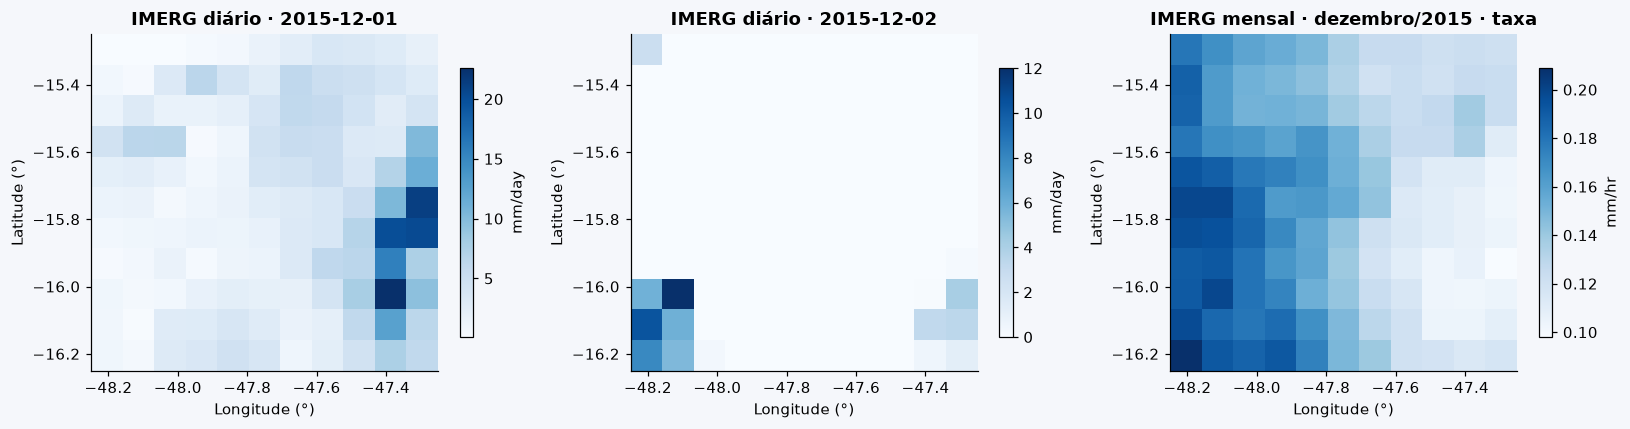

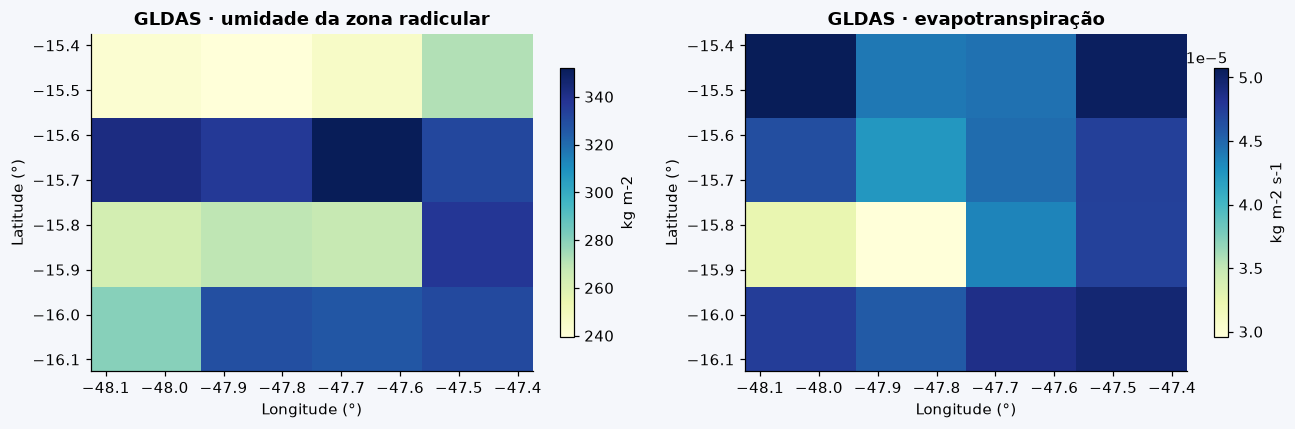

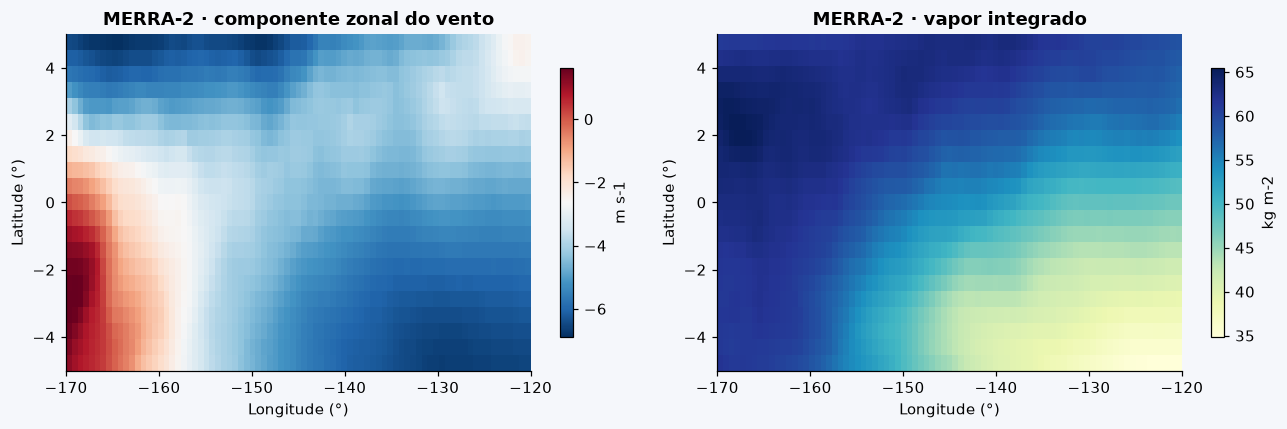

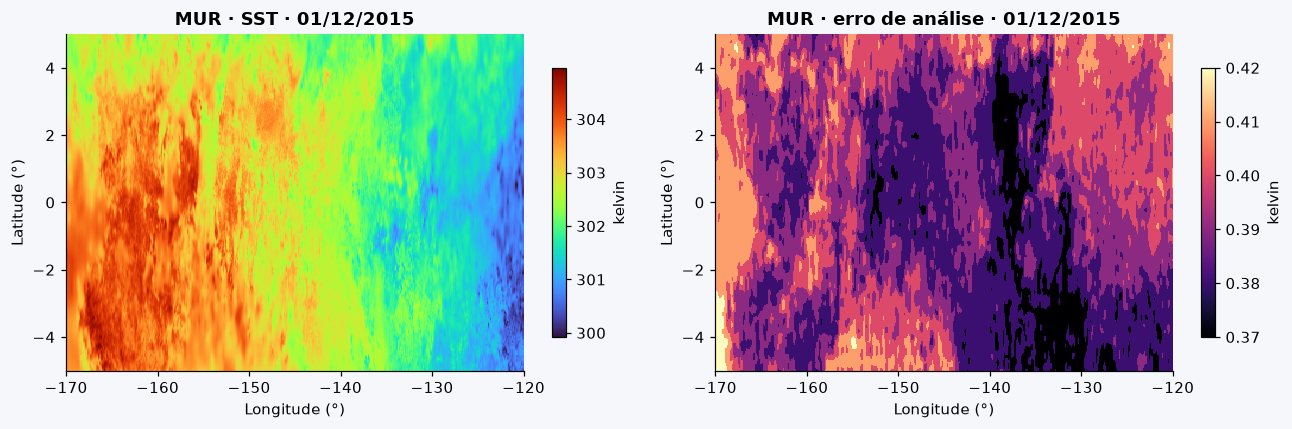

In [6]:
def show_map(entry, name, ax, title, cmap='viridis'):
    raw, missing, attrs, dims = read_field(entry, name)
    image = np.where(missing, np.nan, raw.astype(float))
    image = image * attrs.get('scale_factor', 1) + attrs.get('add_offset', 0)
    spatial_dims = list(dims)
    while image.ndim > 2:
        axis = next((i for i, dim in enumerate(spatial_dims) if dim.lower() == 'time'), 0)
        image = np.take(image, 0, axis=axis)
        spatial_dims.pop(axis)
    lat_axis = next(i for i, dim in enumerate(spatial_dims) if dim.lower() in ('lat', 'latitude'))
    if lat_axis != 0:
        image = image.T
    coords = entry['audit']['coordinates']
    lat = next(v for k, v in coords.items() if k.split('/')[-1].lower() in ('lat', 'latitude'))
    lon = next(v for k, v in coords.items() if k.split('/')[-1].lower() in ('lon', 'longitude'))
    sy, sx = max(1, int(np.ceil(image.shape[0] / 400))), max(1, int(np.ceil(image.shape[1] / 400)))
    view = image[::sy, ::sx]
    plot = ax.imshow(view, origin='lower', aspect='auto', interpolation='nearest', cmap=cmap,
                     extent=[lon['min'], lon['max'], lat['min'], lat['max']])
    ax.set(title=title, xlabel='Longitude (°)', ylabel='Latitude (°)')
    plt.colorbar(plot, ax=ax, label=attrs.get('units', 'unidade não informada'), shrink=.8)

def entries(dataset):
    return sorted([f for f in files if f['dataset'] == dataset], key=lambda f: str(f['audit'].get('observation_period')))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, entry in zip(axes[:2], entries('gpm_daily')):
    show_map(entry, 'precipitation', ax, 'IMERG diário · ' + entry['audit']['observation_period']['start'][:10], 'Blues')
show_map(entries('gpm_monthly')[0], 'Grid/precipitation', axes[2], 'IMERG mensal · dezembro/2015 · taxa', 'Blues')
fig.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
show_map(entries('gldas')[0], 'RootMoist_inst', axes[0], 'GLDAS · umidade da zona radicular', 'YlGnBu')
show_map(entries('gldas')[0], 'Evap_tavg', axes[1], 'GLDAS · evapotranspiração', 'YlGnBu')
fig.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
show_map(entries('merra2')[0], 'U10M', axes[0], 'MERRA-2 · componente zonal do vento', 'RdBu_r')
show_map(entries('merra2')[0], 'TQV', axes[1], 'MERRA-2 · vapor integrado', 'YlGnBu')
fig.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
show_map(entries('mur_sst')[0], 'analysed_sst', axes[0], 'MUR · SST · 01/12/2015', 'turbo')
show_map(entries('mur_sst')[0], 'analysis_error', axes[1], 'MUR · erro de análise · 01/12/2015', 'magma')
fig.tight_layout()
plt.show()

## 6 · Metadados para decidir sobre limpeza
Exemplo de atributos originais: unidade, FillValue, escala, faixa válida e definição da variável. Troque os dois campos abaixo para consultar outra camada. GLDAS é modelo de superfície; MERRA-2 é reanálise; MUR é análise L4. Valores fisicamente incomuns não devem ser apagados sem contexto.

In [7]:
DATASET = 'gldas'
VARIABLE = 'RootMoist_inst'
entry = entries(DATASET)[0]
_, _, attrs, dims = read_field(entry, VARIABLE)
display(pd.DataFrame({'atributo': list(attrs), 'valor_original': [str(v) for v in attrs.values()]}))
display(Markdown('**Proveniência deste arquivo:**'))
display({key: entry.get(key) for key in ('product', 'version', 'collection_id', 'doi',
         'region', 'requested_period', 'granule_observation_period', 'source_url',
         'harmony_job_id', 'retrieved_at_utc', 'retrieved_at_local', 'sha256')})

,atributo,valor_original
0,standard_name,root_zone_soil_moisture
1,long_name,Root zone soil moisture
2,units,kg m-2
3,_FillValue,-9999.0
4,missing_value,-9999.0
5,cell_methods,time: mean
6,vmin,2.0
7,vmax,891.8663


**Proveniência deste arquivo:**

{'product': 'GLDAS_NOAH025_M',
 'version': '2.1',
 'collection_id': 'C1342986036-GES_DISC',
 'doi': '10.5067/SXAVCZFAQLNO',
 'region': {'description': 'Caixa provisória de 1 grau próxima de Brasília, somente para verificar transferência de grades terrestres com baixo volume; não é área de estudo aprovada, polígono de bacia nem evidência de cobertura de estações ANA.',
  'crs': 'EPSG:4326',
  'domain': 'land',
  'provisional': True,
  'bbox': [-48.25, -16.25, -47.25, -15.25],
  'id': 'brasilia_smoke',
  'extraction': 'bounding_box',
  'geometry_id': 'e2ae1810deb9b58ce574a78359b0c6aeca602b2638695ca5b3aaaea044727cab'},
 'requested_period': {'start': '2015-12-01T00:00:00+00:00',
  'end': '2015-12-31T23:59:59.999999+00:00'},
 'granule_observation_period': {'start': '2015-12-01T00:00:00.000Z',
  'end': '2015-12-31T23:59:59.000Z'},
 'source_url': ['https://data.gesdisc.earthdata.nasa.gov/data/GLDAS/GLDAS_NOAH025_M.2.1/2015/GLDAS_NOAH025_M.A201512.021.nc4'],
 'harmony_job_id': '1d9d21dd-6fd0-4

## 7 · Anotações para nossa revisão
| Item | O que observar | Decisão nesta etapa |
|---|---|---|
| Ausências | NaN, FillValue e missing_value no quadro de qualidade | Preservar; não substituir por zero |
| Faixas e extremos | Unidades, escala declarada e atributos de qualidade | Investigar antes de remover qualquer valor |
| Tempo | Cobertura mensal versus timestamp e trimestres RONI sobrepostos | Não juntar séries automaticamente |
| Espaço | Grades distintas e caixa brasileira provisória | Não reamostrar nem assumir precisão local |
| Cobertura histórica | Apenas dois dias e um mês NASA | Ampliar a coleta antes de estudar lacunas ou tendências |

**Suas anotações:**
- Variáveis que merecem inspeção adicional:
- Região/bacia que devemos avaliar:
- Período que precisamos coletar:
- Tratamentos candidatos e suas justificativas:

Nenhum tratamento definitivo foi aplicado. A decisão de limpeza fica para nossa revisão conjunta.

In [8]:
assert all(digest(DATA / path) == expected for path, expected in original_hashes.items())
print('Conferência final: todos os arquivos brutos permanecem idênticos ao manifesto.')

Conferência final: todos os arquivos brutos permanecem idênticos ao manifesto.
